<a href="https://colab.research.google.com/github/loukouma-debug/Machine-learning/blob/main/Pratical.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Practical 1


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os
import csv
import numpy as np
import random

In [ ]:
!cp "/content/drive/MyDrive/ml-32m/ratings.csv" .

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import random



user_to_index = {}
index_to_user = []

data_by_user = []

item_to_index = {}
index_to_item = []

data_by_item = []



with open("ratings.csv") as ratings:
  ratings.readline()
  for line in ratings:
    row = line.split(",")
    userId = row[0]
    movieId = row[1]
    rating = float(row[2])
    if userId not in user_to_index:
      user_to_index[userId] = len(user_to_index)
      index_to_user.append(userId)
      data_by_user.append([])

    if movieId not in item_to_index:
      item_to_index[movieId] = len(item_to_index)
      index_to_item.append(movieId)
      data_by_item.append([])

    data_by_user[user_to_index[userId]].append([item_to_index[movieId], rating])
    data_by_item[item_to_index[movieId]].append([user_to_index[userId], rating])

In [ ]:
print(len(data_by_user))
print(len(data_by_item))

200948
84432


In [ ]:
print(len(data_by_user[0]))


141


In [ ]:
rating_list = [r[1] for l in data_by_user for r in l ]
rating, count =np.unique(rating_list, return_counts=True)

<BarContainer object of 10 artists>

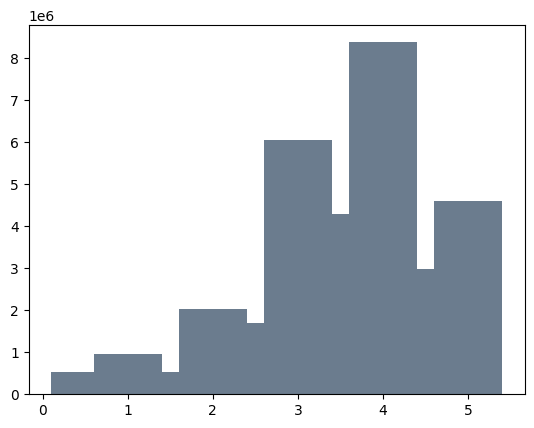

In [ ]:
plt.bar(rating, count, color="#6B7C8E")

<function matplotlib.pyplot.show(close=None, block=None)>

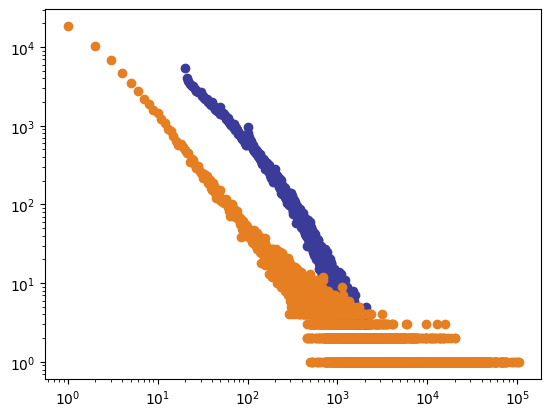

In [ ]:
user_degre1= [len(el) for el in data_by_user]
degre1, count1 = np.unique(user_degre1, return_counts= True)

item_degre2 = [len(el) for el in data_by_item]
degre2, count2 = np.unique(item_degre2, return_counts= True )

plt.scatter(degre1,count1, color="#3B3B9A")
plt.scatter(degre2, count2, color="#E67E22")
plt.xscale("log")
plt.yscale("log")
plt.show

In [ ]:
data_by_item=[]
data_by_user=[]

#Pratical 2


data_by_user_train and data_by_user_test

data_by_movie_train and data_by_movie_test

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!cp "/content/drive/MyDrive/ml-32m/small.csv" .

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import random



user_to_index = {}
index_to_user = []

data_by_user = []

item_to_index = {}
index_to_item = []

data_by_item = []



with open("small.csv") as ratings:
  ratings.readline()
  for line in ratings:
    row = line.split(",")
    userId = row[0]
    movieId = row[1]
    rating = float(row[2])
    if userId not in user_to_index:
      user_to_index[userId] = len(user_to_index)
      index_to_user.append(userId)
      data_by_user.append([])

    if movieId not in item_to_index:
      item_to_index[movieId] = len(item_to_index)
      index_to_item.append(movieId)
      data_by_item.append([])

    data_by_user[user_to_index[userId]].append([item_to_index[movieId], rating])
    data_by_item[item_to_index[movieId]].append([user_to_index[userId], rating])

In [ ]:
# 1. Initialize empty lists for all users and movies
ratings_by_user_train = [[] for _ in range(len(data_by_user))]
ratings_by_user_test = [[] for _ in range(len(data_by_user))]
ratings_by_item_train = [[] for _ in range(len(data_by_item))]
ratings_by_item_test = [[] for _ in range(len(data_by_item))]

# 2. Iterate through every rating and assign it to train or test
for u_idx, user_ratings in enumerate(data_by_user):
    for m_idx, rating in user_ratings:

        # 80% probability of going to the training set
        if random.random() > 0.2:
            ratings_by_user_train[u_idx].append((m_idx, rating))
            ratings_by_item_train[m_idx].append((u_idx, rating))

        # 20% probability of going to the testing set
        else:
            ratings_by_user_test[u_idx].append((m_idx, rating))
            ratings_by_item_test[m_idx].append((u_idx, rating))

In [ ]:
#data_by_item=[]
#data_by_user=[]

In [ ]:
M = len(ratings_by_user_train)
N = len(ratings_by_item_train)
print(N)

10225


In [ ]:
user_biais = np.zeros((M))
item_biais = np.zeros((N))

lamb = 0.1
gamma = 0.1

epochs = 10
train_rmses = []
test_rmses = []
losses = []

for epoch in range(epochs):

  # mise a jour des biais pour les users
  for u in range(M):
    biais = 0
    user_counter =0
    for el in ratings_by_user_train[u]:
      if len(el) > 0:
        i,r = el
        biais += lamb*(r-item_biais[i])
        user_counter +=1
    user_biais[u]= biais/(lamb*user_counter+gamma)

  # pour les items
  for i in range(N):
    biais = 0
    item_counter =0
    for el in ratings_by_item_train[i]:
      if len(el) > 0:
        u,r = el
        biais += lamb*(r-user_biais[u])
        item_counter +=1
    item_biais[i]= biais/(lamb*item_counter+gamma)


  # RSME
  som_error_sqrt = 0
  rate_nber=0

  for  u in range(M):
    for el in ratings_by_user_train[u]:
      if len(el) > 0 :
        i,r = el
        prediction = user_biais[u] + item_biais[i]
        som_error_sqrt += (r - prediction)**2
        rate_nber+=1
  rmse_train = (som_error_sqrt / rate_nber)**0.5
  train_rmses.append(rmse_train)

  #loss
  reg_user = sum([b**2 for b in user_biais])
  reg_item = sum([b**2 for b in item_biais])
  loss = (lamb/2)*som_error_sqrt + (gamma/2)*(reg_user + reg_item)
  losses.append(loss)

  #RMSE for test
  som_error_sqrt_test= 0
  rate_nber_test = 0
  for u in range(M):
    for el in ratings_by_user_test[u]:
      if len(el) > 0 :
        i,r = el
        prediction = user_biais[u]+item_biais[i]
        som_error_sqrt_test += (r-prediction)**2
        rate_nber_test +=1

  rmse_test = (som_error_sqrt_test/rate_nber_test)**2
  test_rmses.append(rmse_test)

  print(f"epoch{epoch + 1} | Train RMSE :{rmse_train:.4f} | Test RMSE: {rmse_test:.4f} | Loss : {loss:.0f}")

epoch1 | Train RMSE :0.8315 | Test RMSE: 0.7309 | Loss : 3290
epoch2 | Train RMSE :0.8201 | Test RMSE: 0.7015 | Loss : 3207
epoch3 | Train RMSE :0.8192 | Test RMSE: 0.6992 | Loss : 3194
epoch4 | Train RMSE :0.8190 | Test RMSE: 0.6987 | Loss : 3186
epoch5 | Train RMSE :0.8189 | Test RMSE: 0.6984 | Loss : 3180
epoch6 | Train RMSE :0.8189 | Test RMSE: 0.6982 | Loss : 3175
epoch7 | Train RMSE :0.8189 | Test RMSE: 0.6983 | Loss : 3170
epoch8 | Train RMSE :0.8190 | Test RMSE: 0.6984 | Loss : 3167
epoch9 | Train RMSE :0.8190 | Test RMSE: 0.6986 | Loss : 3164
epoch10 | Train RMSE :0.8191 | Test RMSE: 0.6988 | Loss : 3161


<function matplotlib.pyplot.show(close=None, block=None)>

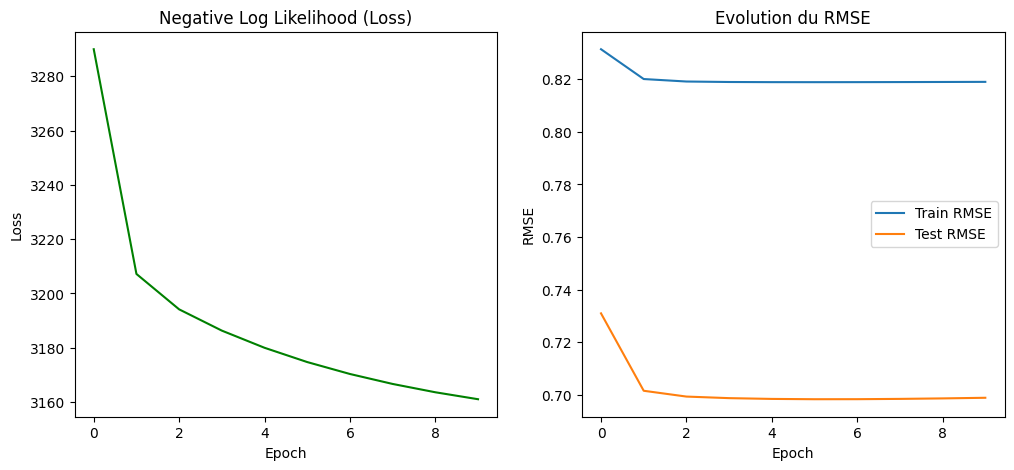

In [ ]:
plt.figure(figsize=(12, 5))

# loss graph
plt.subplot(1,2,1)
plt.plot(losses, color='green')
plt.title("Negative Log Likelihood (Loss)")
plt.xlabel("Epoch")
plt.ylabel("Loss")

# RMSE graph
plt.subplot(1,2,2)
plt.plot(train_rmses, label="Train RMSE")
plt.plot(test_rmses, label="Test RMSE")
plt.title("Evolution du RMSE")
plt.xlabel("Epoch")
plt.ylabel("RMSE")
plt.legend()

plt.show

# Pratical3

In [ ]:
# 1. Initialize empty lists for all users and movies
ratings_by_user_train = [[] for _ in range(len(data_by_user))]
ratings_by_user_test = [[] for _ in range(len(data_by_user))]
ratings_by_item_train = [[] for _ in range(len(data_by_item))]
ratings_by_item_test = [[] for _ in range(len(data_by_item))]

# 2. Iterate through every rating and assign it to train or test
for u_idx, user_ratings in enumerate(data_by_user):
    for m_idx, rating in user_ratings:

        # 80% probability of going to the training set
        if random.random() > 0.2:
            ratings_by_user_train[u_idx].append((m_idx, rating))
            ratings_by_item_train[m_idx].append((u_idx, rating))

        # 20% probability of going to the testing set
        else:
            ratings_by_user_test[u_idx].append((m_idx, rating))
            ratings_by_item_test[m_idx].append((u_idx, rating))

In [ ]:
M = len(ratings_by_user_train)
N = len(ratings_by_item_train)
print(N)

10225


In [ ]:
U = np.zeros((2,3))
print(U)

[[0. 0. 0.]
 [0. 0. 0.]]


In [ ]:
user_biais = np.zeros((M))
item_biais = np.zeros((N))
K=10
U = np.zeros((M,K))
V = np.zeros((N,K))

tau = 0.1
lamb = 0.1
gamma = 0.1

epochs = 10
train_rmses = []
test_rmses = []
losses = []
b = np.zeros((K))
c = np.zeros((K))
A= np.zeros((K,K))
B= np.zeros((K,K))
I = np.identity((K))

for epoch in range(epochs):

  # update user bias and vector
  for u in range(M):
    error = 0
    user_counter =0
    for el in ratings_by_user_train[u]:
      if len(el) > 0:
        i,r = el
        prediction_1= (np.dot(U[u], V[i]) + item_biais[i])
        error += r- prediction_1
        user_counter +=1
    user_biais[u]= lamb*error/(lamb*user_counter+gamma)

    for el in ratings_by_user_train[u]:
      if len(el) > 0:
        i,r = el
        b += V[i]*(r - user_biais[u] - item_biais[i])
        A += np.outer(V[i],V[i].T)
      A += r*I
      A = lamb*A
      U[u]= np.linalg.solve(A, lamb*b)



  # for items and their vector
  for i in range(N):
    error = 0
    item_counter =0
    for el in ratings_by_item_train[i]:
      if len(el) > 0:
        u,r = el
        prediction_2 = (np.dot(V[i],U[u])) + user_biais[u]
        error += r - prediction_2
        item_counter +=1
    item_biais[i]= lamb*error/(lamb*item_counter+gamma)

    for el in ratings_by_item_train[i]:
      if len(el) > 0:
        u,r = el
        c += U[u]*(r - user_biais[u] - item_biais[i])
        B += np.outer(U[u],U[u].T)
      B += r*I
      B = lamb*B
      V[i] = np.linalg.solve(B, lamb*c)



  # RSME train
  som_error_sqrt = 0
  rate_nber = 0

  for  u in range(M):
    for el in ratings_by_user_train[u]:
      if len(el) > 0 :
        i,r = el
        prediction = np.dot(U[u], V[i]) + user_biais[u] + item_biais[i]
        som_error_sqrt += (r - prediction)**2
        rate_nber += 1
  rmse_train = (som_error_sqrt / rate_nber)**0.5
  train_rmses.append(rmse_train)

  #loss
  reg_user_bias = np.sum(user_biais**2)
  reg_item_bias = np.sum(item_biais**2)
  reg_user_vector = np.sum(U**2)
  reg_item_vector = np.sum(V**2)
  loss = (lamb/2)*som_error_sqrt + (gamma/2)*(reg_user_bias + reg_item_bias)+ (tau/2)*(reg_user_vector + reg_item_vector)
  losses.append(loss)

  #RMSE for test
  som_error_sqrt_test= 0
  rate_nber_test = 0
  for  u in range(M):
    for el in ratings_by_user_test[u]:
      if len(el) > 0 :
        i,r = el
        prediction = np.dot(U[u], V[i]) + user_biais[u] + item_biais[i]
        som_error_sqrt += (r - prediction)**2
        rate_nber+=1
  rmse_test = (som_error_sqrt / rate_nber)**0.5
  test_rmses.append(rmse_test)

  print(f"epoch{epoch + 1} | Train RMSE :{rmse_train:.4f} | Test RMSE: {rmse_test:.4f} | Loss : {loss:.0f}")

epoch1 | Train RMSE :0.8297 | Test RMSE: 0.8504 | Loss : 3278
epoch2 | Train RMSE :0.8185 | Test RMSE: 0.8394 | Loss : 3196
epoch3 | Train RMSE :0.8176 | Test RMSE: 0.8385 | Loss : 3183
epoch4 | Train RMSE :0.8175 | Test RMSE: 0.8383 | Loss : 3175
epoch5 | Train RMSE :0.8174 | Test RMSE: 0.8383 | Loss : 3169
epoch6 | Train RMSE :0.8174 | Test RMSE: 0.8382 | Loss : 3164
epoch7 | Train RMSE :0.8174 | Test RMSE: 0.8383 | Loss : 3159
epoch8 | Train RMSE :0.8174 | Test RMSE: 0.8383 | Loss : 3156
epoch9 | Train RMSE :0.8175 | Test RMSE: 0.8383 | Loss : 3153
epoch10 | Train RMSE :0.8175 | Test RMSE: 0.8384 | Loss : 3150


<function matplotlib.pyplot.show(close=None, block=None)>

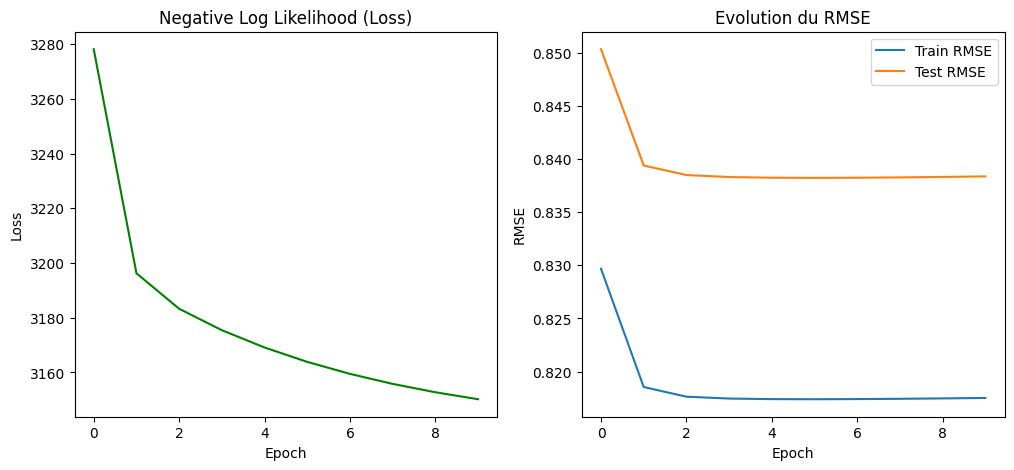

In [ ]:
plt.figure(figsize=(12, 5))

# loss graph
plt.subplot(1,2,1)
plt.plot(losses, color='green')
plt.title("Negative Log Likelihood (Loss)")
plt.xlabel("Epoch")
plt.ylabel("Loss")

# RMSE graph
plt.subplot(1,2,2)
plt.plot(train_rmses, label="Train RMSE")
plt.plot(test_rmses, label="Test RMSE")
plt.title("Evolution du RMSE")
plt.xlabel("Epoch")
plt.ylabel("RMSE")
plt.legend()

plt.show

# Pratical 4

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!cp "/content/drive/MyDrive/ml-32m/ratings.csv" .

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import random



user_to_index = {}
index_to_user = []

data_by_user = []

item_to_index = {}
index_to_item = []

data_by_item = []



with open("ratings.csv") as ratings:
  ratings.readline()
  for line in ratings:
    row = line.split(",")
    userId = row[0]
    movieId = row[1]
    rating = float(row[2])
    if userId not in user_to_index:
      user_to_index[userId] = len(user_to_index)
      index_to_user.append(userId)
      data_by_user.append([])

    if movieId not in item_to_index:
      item_to_index[movieId] = len(item_to_index)
      index_to_item.append(movieId)
      data_by_item.append([])

    data_by_user[user_to_index[userId]].append([item_to_index[movieId], rating])
    data_by_item[item_to_index[movieId]].append([user_to_index[userId], rating])

In [4]:
# 1. Initialize empty lists for all users and movies
ratings_by_user_train = [[] for _ in range(len(data_by_user))]
ratings_by_user_test = [[] for _ in range(len(data_by_user))]
ratings_by_item_train = [[] for _ in range(len(data_by_item))]
ratings_by_item_test = [[] for _ in range(len(data_by_item))]

# 2. Iterate through every rating and assign it to train or test
for u_idx, user_ratings in enumerate(data_by_user):
    for m_idx, rating in user_ratings:

        # 80% probability of going to the training set
        if random.random() > 0.2:
            ratings_by_user_train[u_idx].append((m_idx, rating))
            ratings_by_item_train[m_idx].append((u_idx, rating))

        # 20% probability of going to the testing set
        else:
            ratings_by_user_test[u_idx].append((m_idx, rating))
            ratings_by_item_test[m_idx].append((u_idx, rating))

In [5]:
M = len(ratings_by_user_train)
N = len(ratings_by_item_train)
user_biais = np.zeros((M))
item_biais = np.zeros((N))
K=10
U = np.zeros((M,K))
V = np.zeros((N,K))

tau = 0.1
lamb = 0.1
gamma = 0.1

epochs = 10
train_rmses = []
test_rmses = []
losses = []
b = np.zeros((K))
c = np.zeros((K))
A= np.zeros((K,K))
B= np.zeros((K,K))
I = np.identity((K))

for epoch in range(epochs):

  # update user bias and vector
  for u in range(M):
    error = 0
    user_counter =0
    for el in ratings_by_user_train[u]:
      if len(el) > 0:
        i,r = el
        prediction_1= (np.dot(U[u], V[i]) + item_biais[i])
        error += r- prediction_1
        user_counter +=1
    user_biais[u]= lamb*error/(lamb*user_counter+gamma)

    for el in ratings_by_user_train[u]:
      if len(el) > 0:
        i,r = el
        b += V[i]*(r - user_biais[u] - item_biais[i])
        A += np.outer(V[i],V[i].T)
      A += r*I
      A = lamb*A
      U[u]= np.linalg.solve(A, lamb*b)



  # for items and their vector
  for i in range(N):
    error = 0
    item_counter =0
    for el in ratings_by_item_train[i]:
      if len(el) > 0:
        u,r = el
        prediction_2 = (np.dot(V[i],U[u])) + user_biais[u]
        error += r - prediction_2
        item_counter +=1
    item_biais[i]= lamb*error/(lamb*item_counter+gamma)

    for el in ratings_by_item_train[i]:
      if len(el) > 0:
        u,r = el
        c += U[u]*(r - user_biais[u] - item_biais[i])
        B += np.outer(U[u],U[u].T)
      B += r*I
      B = lamb*B
      V[i] = np.linalg.solve(B, lamb*c)



  # RSME train
  som_error_sqrt = 0
  rate_nber = 0

  for  u in range(M):
    for el in ratings_by_user_train[u]:
      if len(el) > 0 :
        i,r = el
        prediction = np.dot(U[u], V[i]) + user_biais[u] + item_biais[i]
        som_error_sqrt += (r - prediction)**2
        rate_nber += 1
  rmse_train = (som_error_sqrt / rate_nber)**0.5
  train_rmses.append(rmse_train)

  #loss
  reg_user_bias = np.sum(user_biais**2)
  reg_item_bias = np.sum(item_biais**2)
  reg_user_vector = np.sum(U**2)
  reg_item_vector = np.sum(V**2)
  loss = (lamb/2)*som_error_sqrt + (gamma/2)*(reg_user_bias + reg_item_bias)+ (tau/2)*(reg_user_vector + reg_item_vector)
  losses.append(loss)

  #RMSE for test
  som_error_sqrt_test= 0
  rate_nber_test = 0
  for  u in range(M):
    for el in ratings_by_user_test[u]:
      if len(el) > 0 :
        i,r = el
        prediction = np.dot(U[u], V[i]) + user_biais[u] + item_biais[i]
        som_error_sqrt += (r - prediction)**2
        rate_nber+=1
  rmse_test = (som_error_sqrt / rate_nber)**0.5
  test_rmses.append(rmse_test)

  print(f"epoch{epoch + 1} | Train RMSE :{rmse_train:.4f} | Test RMSE: {rmse_test:.4f} | Loss : {loss:.0f}")

epoch1 | Train RMSE :0.8605 | Test RMSE: 0.8625 | Loss : 1083051
epoch2 | Train RMSE :0.8472 | Test RMSE: 0.8492 | Loss : 1048367
epoch3 | Train RMSE :0.8468 | Test RMSE: 0.8488 | Loss : 1044794
epoch4 | Train RMSE :0.8468 | Test RMSE: 0.8487 | Loss : 1042693
epoch5 | Train RMSE :0.8467 | Test RMSE: 0.8487 | Loss : 1040716
epoch6 | Train RMSE :0.8467 | Test RMSE: 0.8487 | Loss : 1038786
epoch7 | Train RMSE :0.8467 | Test RMSE: 0.8487 | Loss : 1036895
epoch8 | Train RMSE :0.8467 | Test RMSE: 0.8487 | Loss : 1035042
epoch9 | Train RMSE :0.8467 | Test RMSE: 0.8486 | Loss : 1033227
epoch10 | Train RMSE :0.8467 | Test RMSE: 0.8486 | Loss : 1031447


<function matplotlib.pyplot.show(close=None, block=None)>

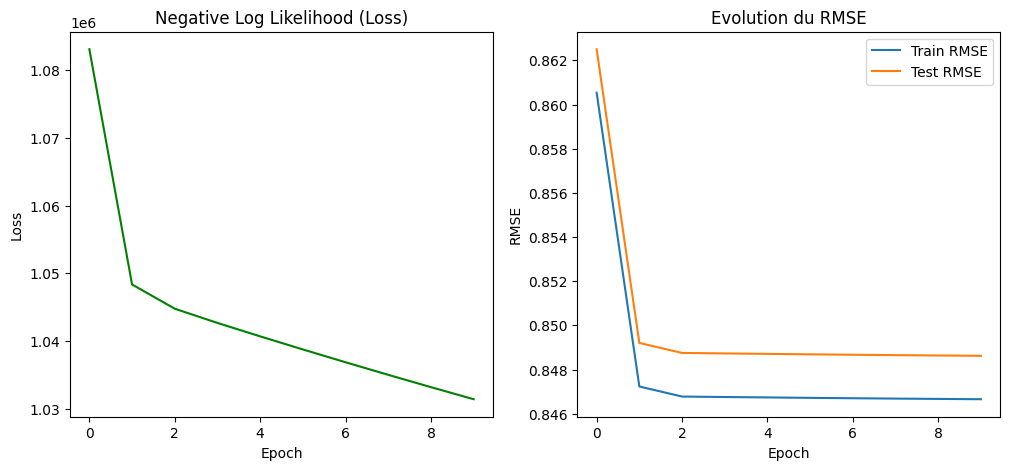

In [6]:
plt.figure(figsize=(12, 5))

# loss graph
plt.subplot(1,2,1)
plt.plot(losses, color='green')
plt.title("Negative Log Likelihood (Loss)")
plt.xlabel("Epoch")
plt.ylabel("Loss")

# RMSE graph
plt.subplot(1,2,2)
plt.plot(train_rmses, label="Train RMSE")
plt.plot(test_rmses, label="Test RMSE")
plt.title("Evolution du RMSE")
plt.xlabel("Epoch")
plt.ylabel("RMSE")
plt.legend()

plt.show

In [ ]:
# def split_data(data_by_user, n_items, p_test=0.2, seed=0):
#     rng = random.Random(seed)
#     ru_tr, ru_te = [[] for _ in data_by_user], [[] for _ in data_by_user]
#     ri_tr, ri_te = [[] for _ in range(n_items)], [[] for _ in range(n_items)]
#     for u, lst in enumerate(data_by_user):
#         for i, r in lst:
#             tr = rng.random() > p_test
#             (ru_tr if tr else ru_te)[u].append((i, r))
#             (ri_tr if tr else ri_te)[i].append((u, r))
#     return ru_tr, ru_te, ri_tr, ri_te

# def rmse(by_user, U, V, bu, bi):
#     err = [(r - (U[u] @ V[i] + bu[u] + bi[i]))**2 for u, l in enumerate(by_user) for i, r in l]
#     return float(np.sqrt(np.mean(err)))

# def loss_fn(by_user, U, V, bu, bi, lamb, gamma, tau):
#     sse = sum((r - (U[u] @ V[i] + bu[u] + bi[i]))**2 for u, l in enumerate(by_user) for i, r in l)
#     return (lamb/2)*sse + (gamma/2)*(bu@bu + bi@bi) + (tau/2)*(np.sum(U**2) + np.sum(V**2))

# def update_side(by_x, X, Y, bx, by, lamb, gamma, tau):
#     K = X.shape[1]
#     for x, lst in enumerate(by_x):
#         if not lst: continue
#         idx = np.array([j for j, _ in lst]); r = np.array([v for _, v in lst])
#         Yj = Y[idx]
#         bx[x] = lamb * np.sum(r - by[idx] - Yj @ X[x]) / (lamb*len(r) + gamma)
#         A = lamb * Yj.T @ Yj + tau * np.eye(K)
#         X[x] = np.linalg.solve(A, lamb * Yj.T @ (r - bx[x] - by[idx]))

# def als(ru_tr, ri_tr, ru_te, K=10, lamb=0.1, gamma=0.1, tau=0.1, epochs=15, seed=0):
#     M, N = len(ru_tr), len(ri_tr)
#     rng = np.random.default_rng(seed)
#     U, V = 0.1*rng.standard_normal((M, K)), 0.1*rng.standard_normal((N, K))
#     bu, bi = np.zeros(M), np.zeros(N)
#     hist = {"train": [], "test": [], "loss": []}
#     for ep in range(epochs):
#         update_side(ru_tr, U, V, bu, bi, lamb, gamma, tau)
#         update_side(ri_tr, V, U, bi, bu, lamb, gamma, tau)
#         hist["train"].append(rmse(ru_tr, U, V, bu, bi))
#         hist["test"].append(rmse(ru_te, U, V, bu, bi))
#         hist["loss"].append(loss_fn(ru_tr, U, V, bu, bi, lamb, gamma, tau))
#         print(f"epoch {ep+1} | train {hist['train'][-1]:.4f} | test {hist['test'][-1]:.4f} | loss {hist['loss'][-1]:.0f}")
#     return U, V, bu, bi, hist

# def plot_hist(hist):
#     fig, ax = plt.subplots(1, 2, figsize=(12, 5))
#     ax[0].plot(hist["loss"], color="green"); ax[0].set_title("Loss")
#     ax[1].plot(hist["train"], label="Train"); ax[1].plot(hist["test"], label="Test"); ax[1].legend()
#     ax[1].set_title("RMSE"); plt.show()


# ru_tr, ru_te, ri_tr, ri_te = split_data(data_by_user, len(data_by_item))
# U, V, bu, bi, hist = als(ru_tr, ri_tr, ru_te, K=10)

In [ ]:

plot_hist(hist)